

**Instrucción:** completa esta plantilla con tu diseño y desarrollo. Evita incluir soluciones generadas automáticamente.



In [ ]:
# @title Ingrese datos
nombre_estudiante = "" # @param {"type":"string"}
carnet = None # @param {"type":"integer"}


## 1) Descripción del problema **[1 pts]**
Una plataforma de red social desea analizar las conexiones de amistad entre sus usuarios. Cada
usuario será representado mediante un vértice y cada amistad mediante una arista. El objetivo es
implementar recorridos BFS y DFS y utilizar BFS para encontrar conexiones con la menor cantidad
de saltos

## 2) Requerimientos
####REQUERIMINETOS FUNCIONALES
RQF 1:Mostrar lista de adyacencia<br>
RQF 2:Busqueda por profundidad<br>
RQF 3:Busqueda por anchura<br>
RQF 4:Agragar nuevo inicio <br>
RQF 5:Mostrar ruta entre dos personas<br>
RQF 6:Agregar nuevo usuario, junto a sus conexiones


###REQUERIMINETOS NO FUNCIONALES
RQNF 01 (Eficiencia):Al estar grafos, el programa es mas eficiente al recorrer los datos y al realizar busquedas<br>
RQNF 02 (Mantenibilidad): Ya que el código es modular, es más fácil adaptarlo y modificarlo ademas de estar escrito para evitar ciclos infinitos e interrupciones<br>
RQNF 03 (Corrección): Ya que el código es modular, permite ver las funciónes facilmente si hay un error<br>
RQNF 04 (Programar en Python): Programamos en Python porque el lenguaje Python es un lenguaje facil de comprender el cual se usa más que todo en programas de datos



## 3) Historias de usuario
###HU 01: Mostrar lista de adyacencia

RQF01

Entradas: ninguna (se usa la red cargada al iniciar)

Salidas: cada usuario con la lista de sus amigos directos (ej: Ana : ['Carlos', 'Laura'])

CA: aparecen todos los usuarios y cada amistad se guarda en ambos sentidos

CE: no hay

###HU 02: Búsqueda por anchura (BFS)

RQF02

Entradas: usuario inicial (Ana por defecto, o el que elija el usuario)

Salidas: orden de visita y grado de separación de cada usuario

CA: el usuario existe y ningún usuario se visita dos veces

CE: si el nombre no existe, se muestra "Error: El usuario no existe"

###HU 03: Búsqueda por profundidad (DFS)

RQF03

Entradas: usuario inicial

Salidas: orden de visita del recorrido en profundidad (ej: Ana -> Carlos -> Mateo -> Sofia -> Valentina -> Daniel -> Laura)

CA: el usuario existe y ningún usuario se visita dos veces

CE: si el nombre no existe, se muestra "Error: El usuario no existe"

###HU 04: Mostrar ruta entre dos personas

RQF04

Entradas: usuario inicial y usuario destino

Salidas: ruta con menos conexiones y grados de separación (ej: Ana -> Carlos -> Sofia -> Valentina, 3 grados)

CA: ambos usuarios existen y la ruta se calcula con BFS

CE:

Si alguno no existe: "Error: Uno de los usuarios no existe"

Si no hay conexión: "No existe una conexión entre ambos usuarios"

###HU 05: Agregar nuevo usuario con sus conexiones

RQF05

Entradas: nombre del nuevo usuario y dos usuarios con quienes conectarlo

Salidas: mensaje "Usuario X agregado" y la red actualizada (ej: Juliana conectada con Mateo y Daniel)

CA: el nuevo usuario queda conectado con los dos usuarios indicados, en ambos sentidos

CE: no se registran amistades duplicadas


## 4) Diagramas de flujo 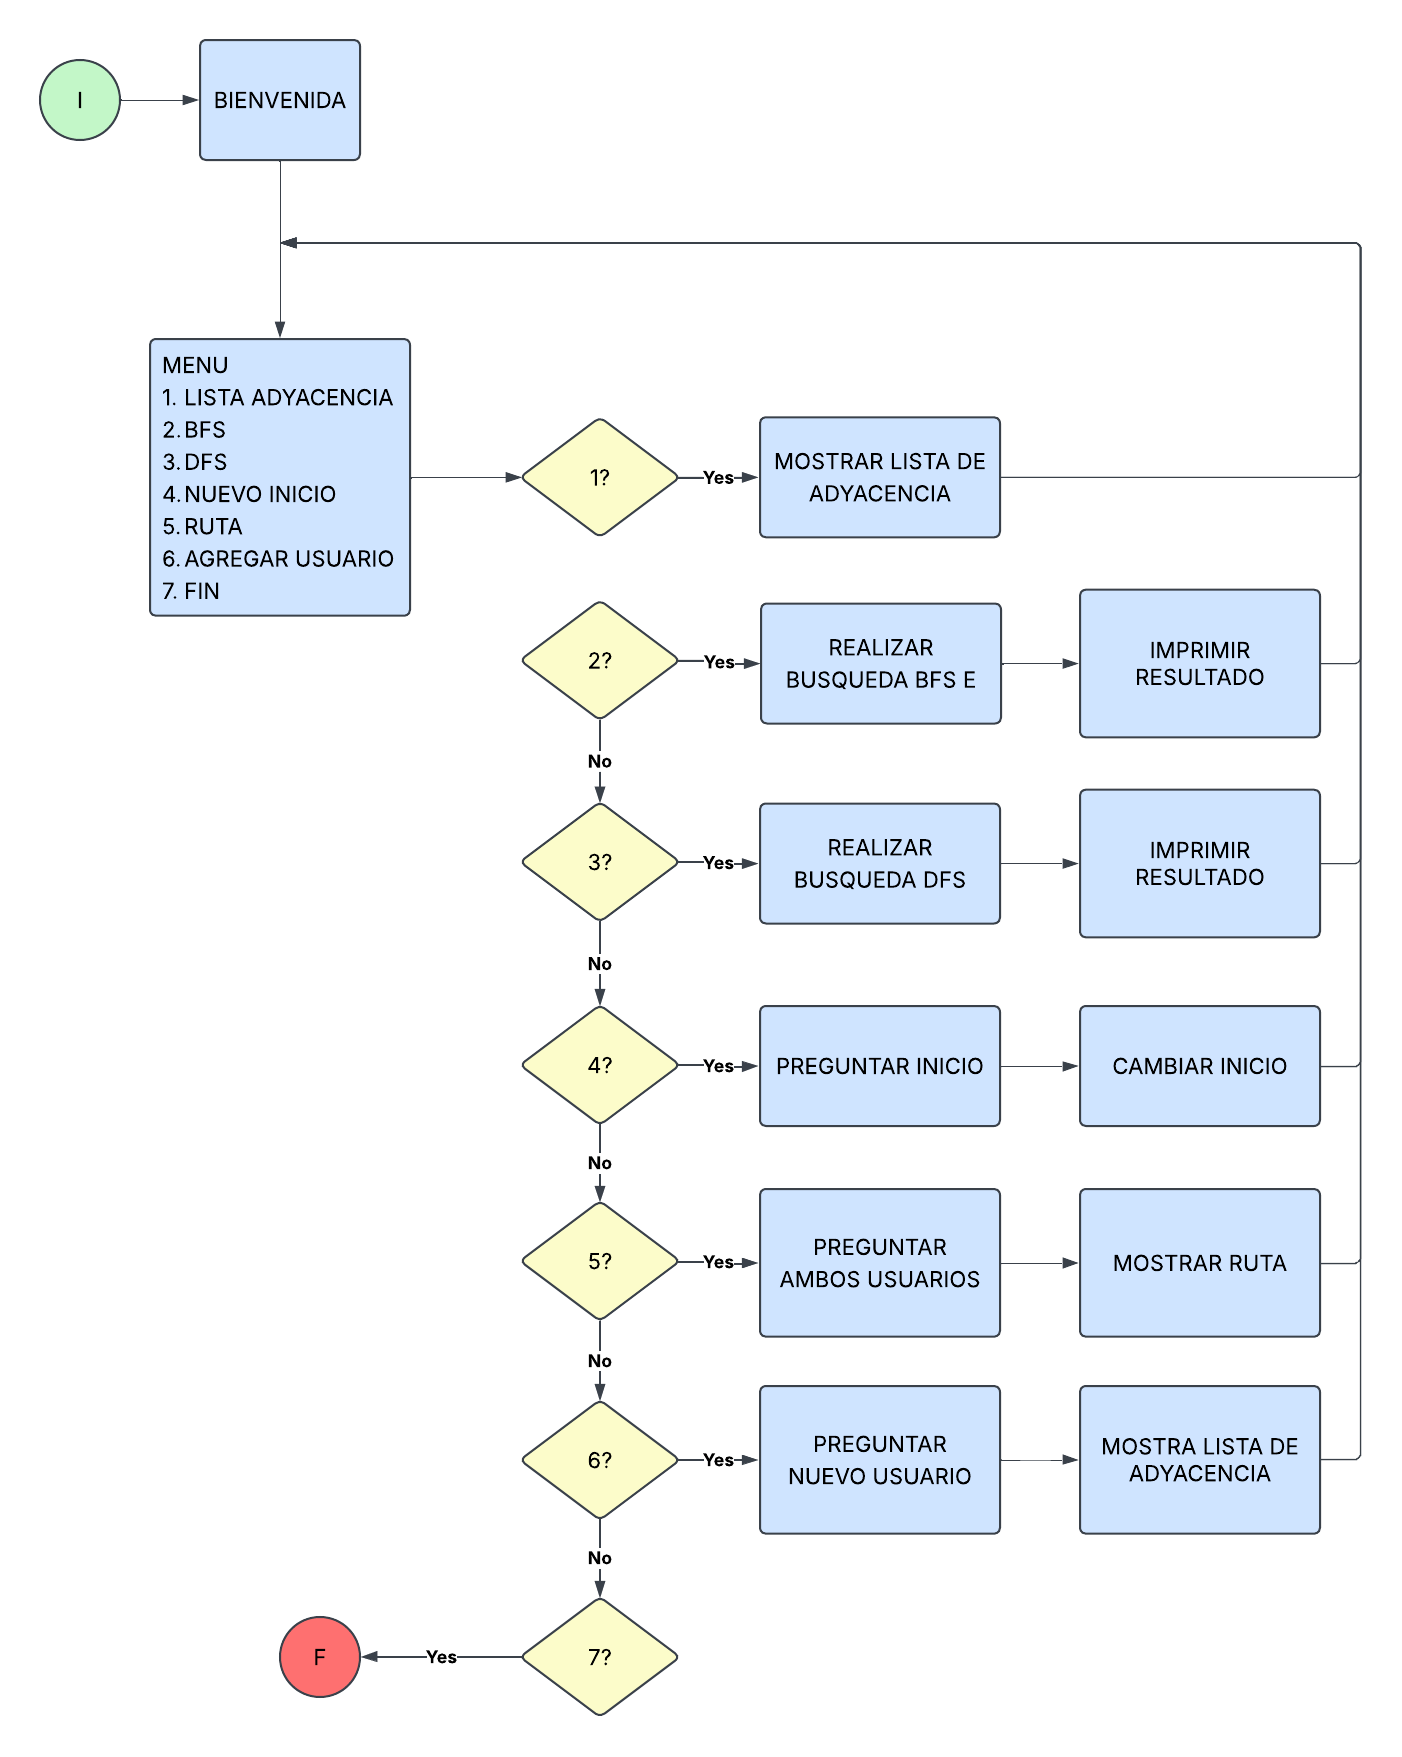


Descripcion del diagrama de flujo:

El programa da una bienvenida al usuario y le da un menu interactivo. En el menu el usuario tendra varias opciones unmeradas del 1 al 7.

Si el usuario digita el 1, el programa mostrara la lista de adyacencia.

Si el usuario digita el 2, el programa realizara la busqueda BFS e imprimira el resultado

Si el usuario digita el 3, el programa realizara la budsqueda DFS e imprimira el resultado

Si el usuario digita el numero 4, el programa preguntara cual es el contacto inicial y lo cambiara para realizar las busquedas

Si el usuario digita el 5, el programa preguntara a ammbos contactos, el de inicio y el de final para poder realizar la busqueda

Si el usuario digita el 6, el programa le preguntara cual es el usuario que desea agregar, preguntando sus conexiones y mostrara la loista de adyacencia

Si el usuario digita el 7, el programa finalizara

### 5) Análisis de complejidad **[15 pts]**
####Búsquedas y Recorridos completos: BFS (bfs) y DFS (dfs)



$O(n^2)$ en el peor de los casos.

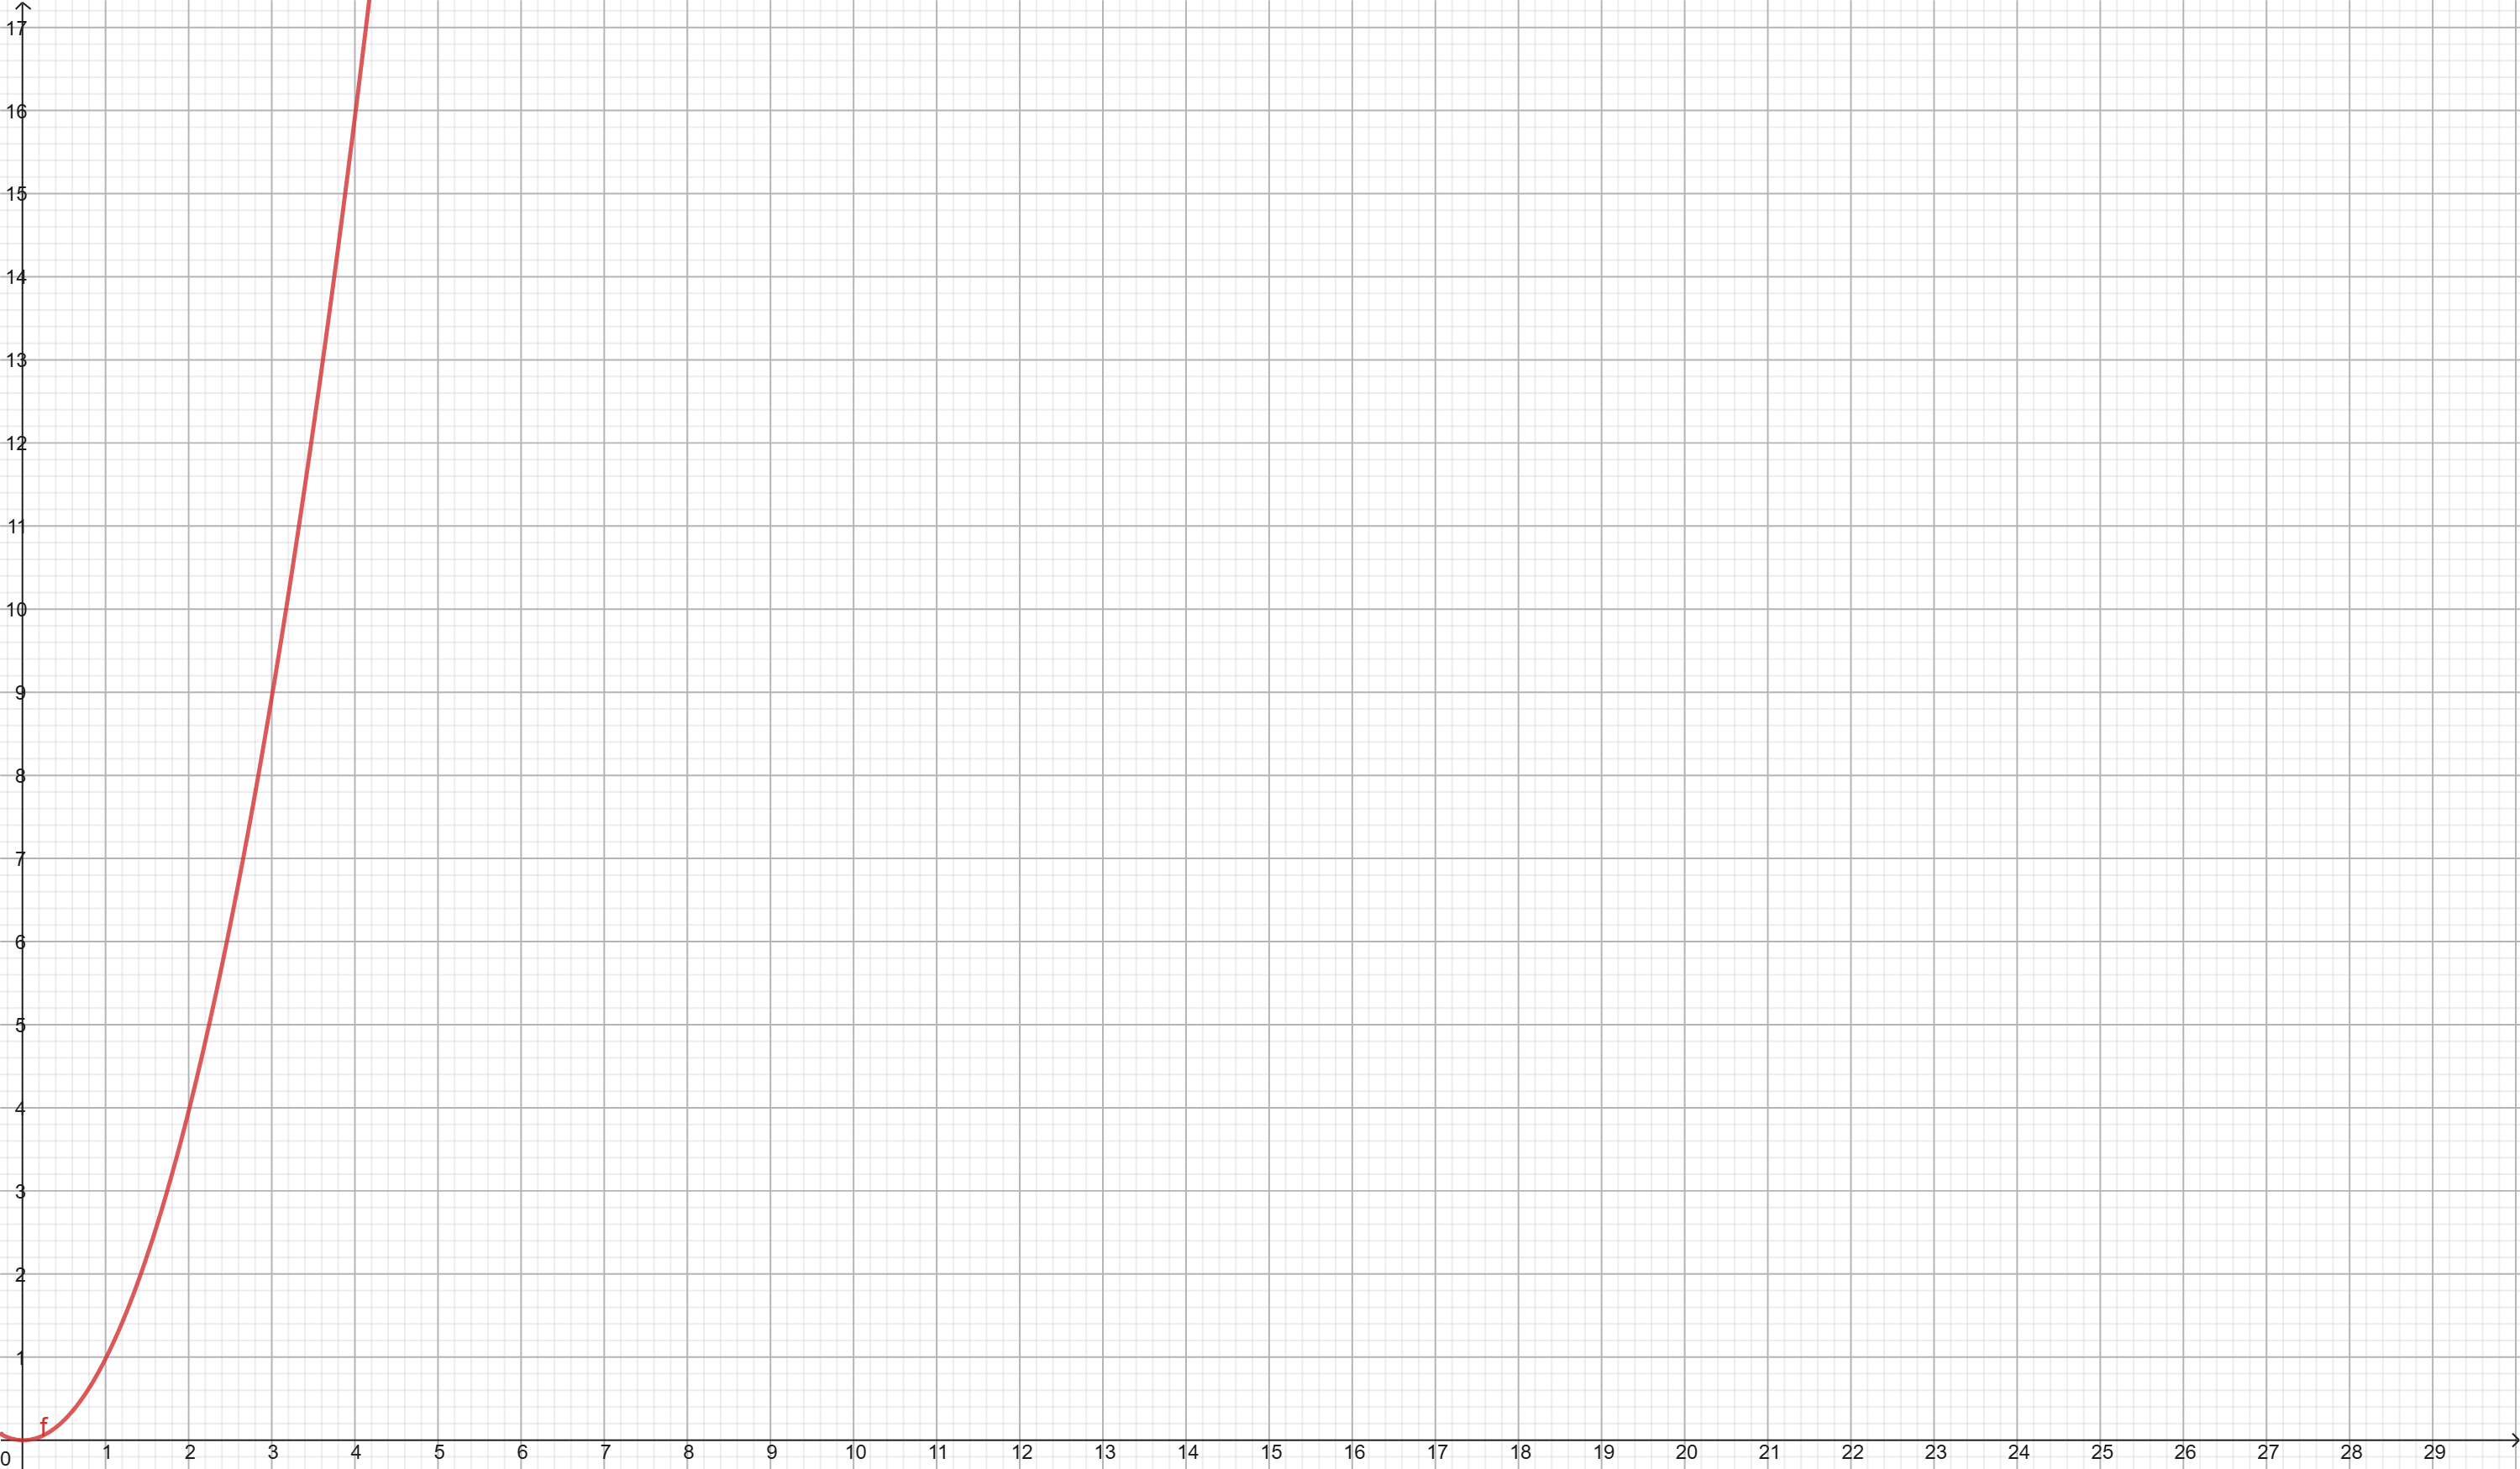

Mejor Caso: $\Omega(1)$.

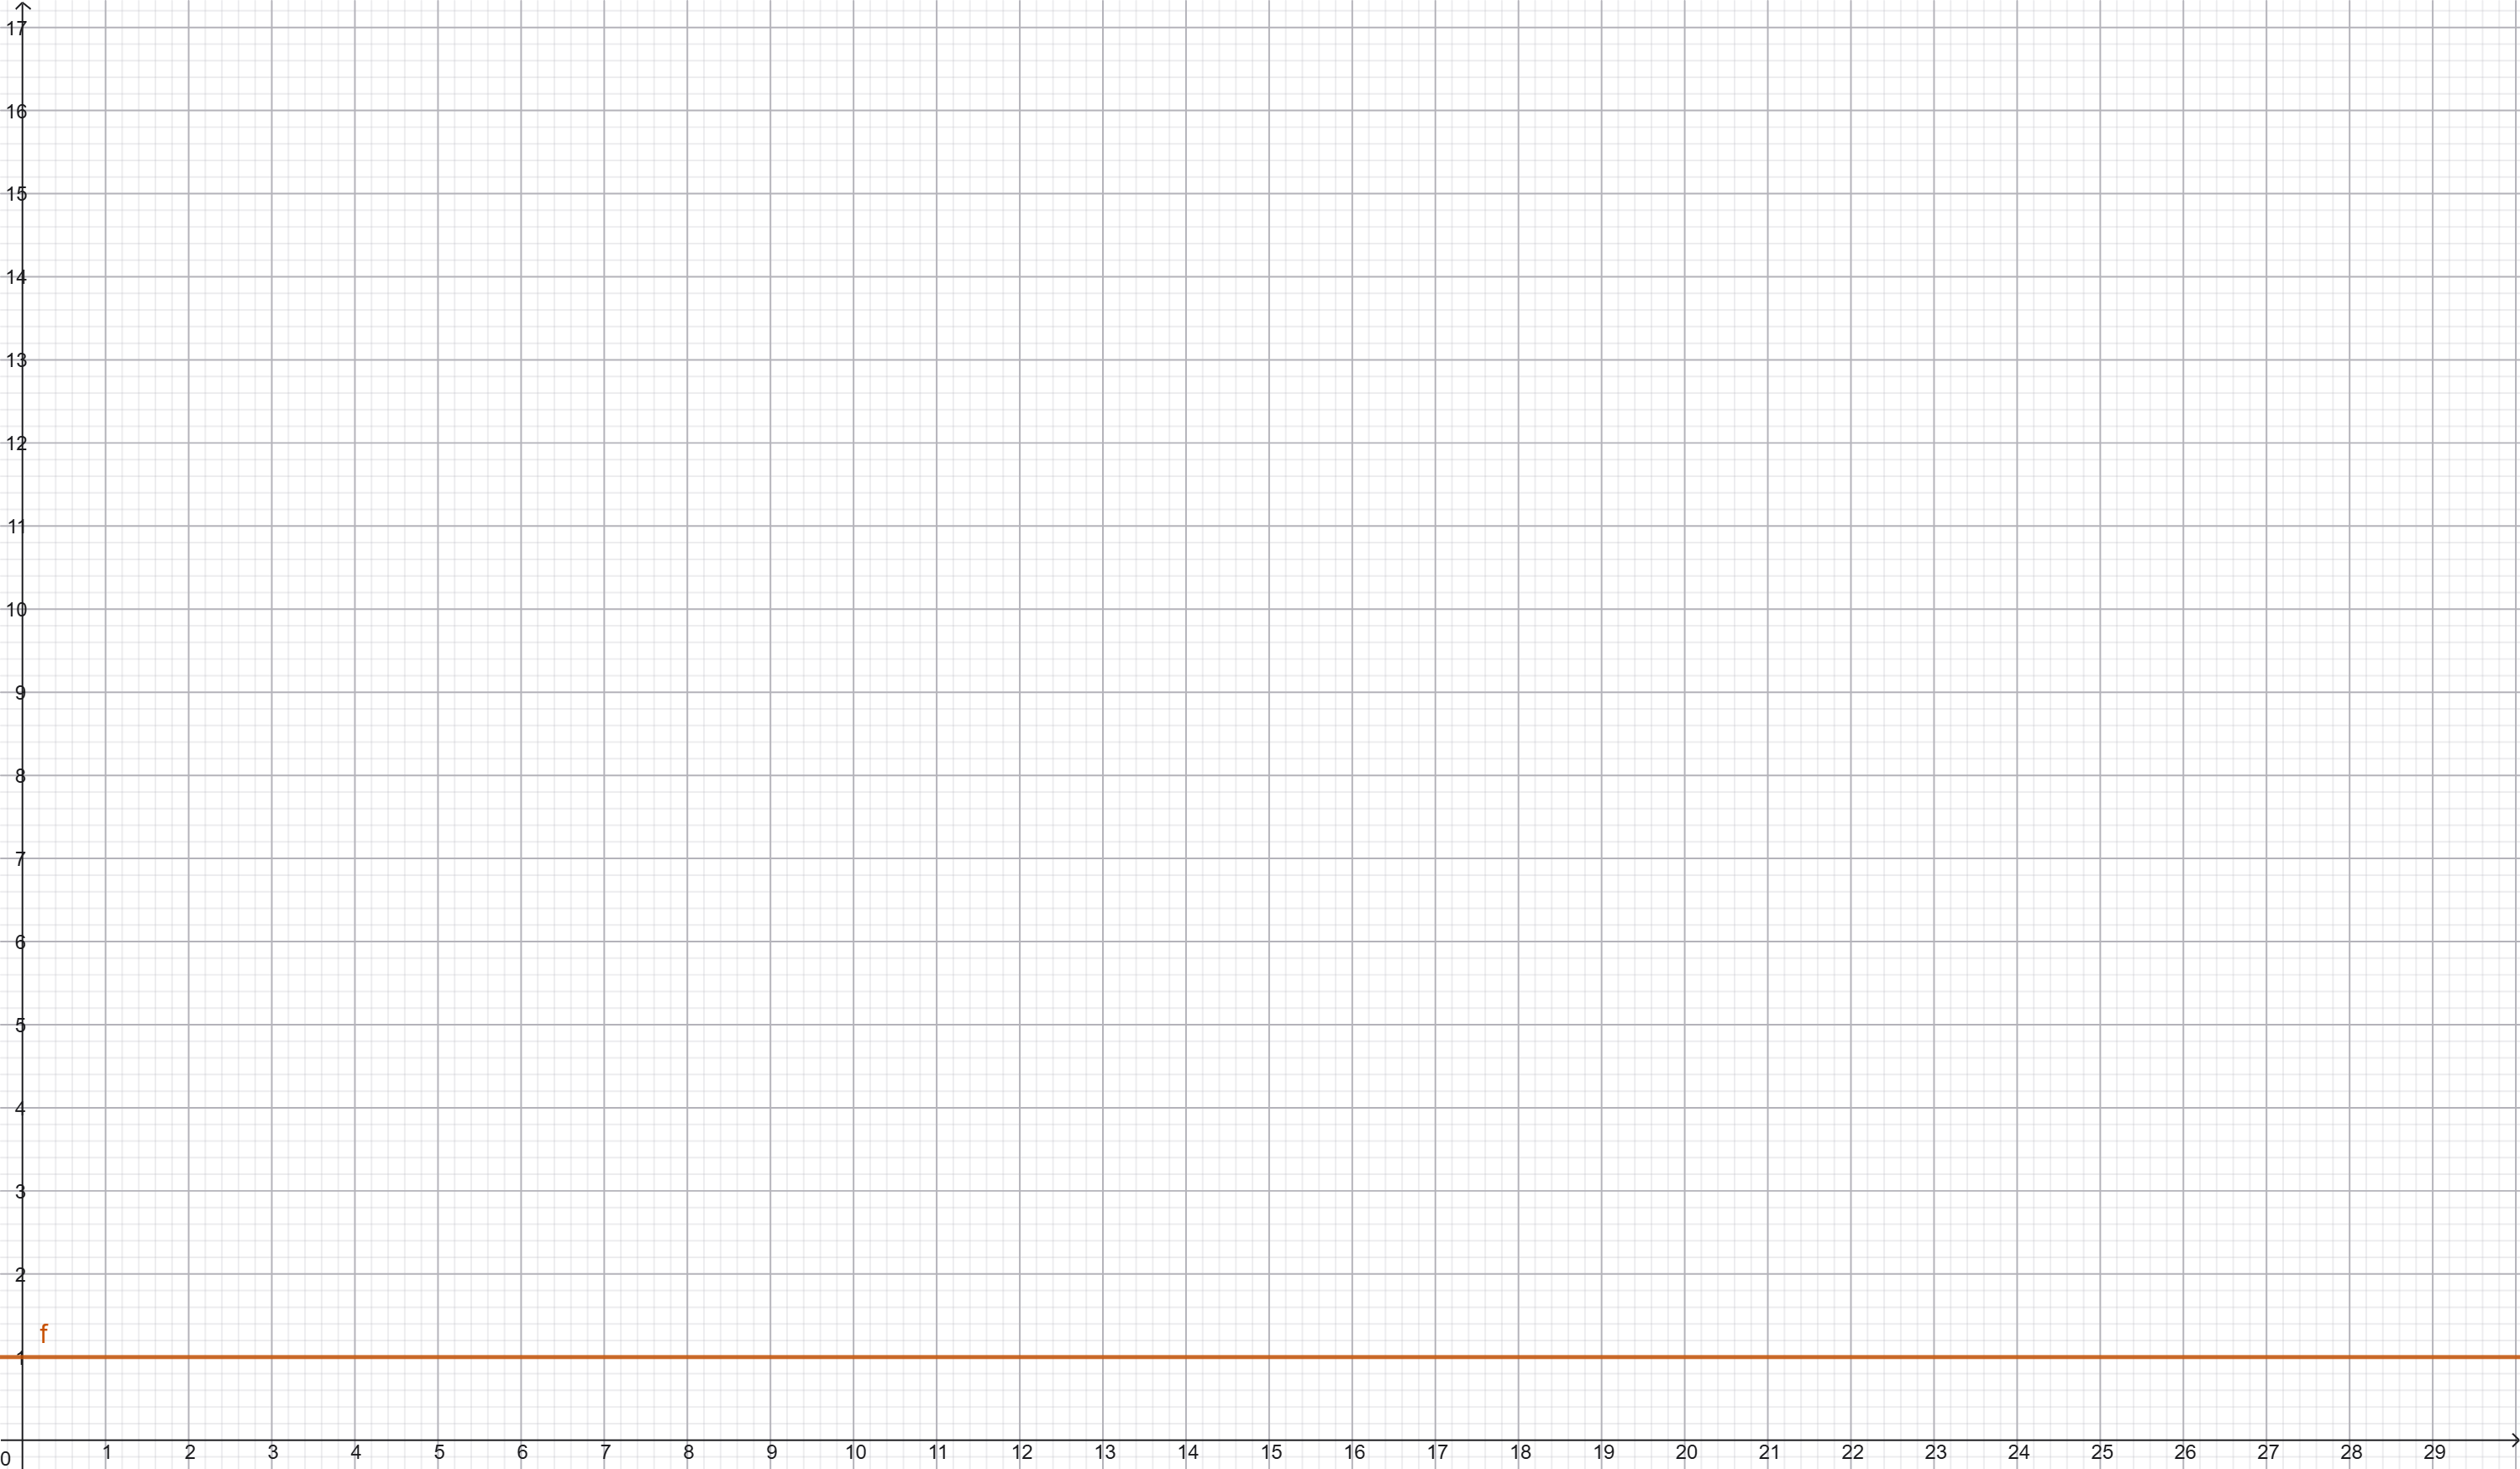

El mejor caso ocurre cuando se evalua un nodo aislado, es decir, que no tiene conexiones, por lo que no es necesario realizar el proceso.

El peor caso se da en los nodos o contactos que estan hiperconectados, ya que visitara los vertices, y al no ser dirigidos los recorrera multiples veces, obteniendo $O(n^2)$



## 6) Código funcional

In [ ]:
from collections import deque

class RedSocial:
   def __init__(self):
       self.grafo = {}
   def añad_usuario(self, usuario):
       if usuario not in self.grafo:
           self.grafo[usuario] = []
   def añad_amist(self, u1, u2):
       self.añad_usuario(u1)
       self.añad_usuario(u2)
       if u2 not in self.grafo[u1]:
           self.grafo[u1].append(u2)
       if u1 not in self.grafo[u2]:
           self.grafo[u2].append(u1)
   def mostrar(self):
       print("\nRed Social")
       for usr in self.grafo:
           amigos_str = ", ".join(self.grafo[usr])
           print(usr + ": " + amigos_str)
   def bfs(self, ini):
       if ini not in self.grafo:
           print("Error: El usuario no existe.")
           return
       visit = []
       cola = deque()
       cola.append([ini, 0])
       visit.append(ini)
       camino = []
       grados = {}
       while len(cola) > 0:
           datos = cola.popleft()
           actual = datos[0]
           grado = datos[1]
           camino.append(actual)
           if grado not in grados:
               grados[grado] = []
           grados[grado].append(actual)
           for amg in self.grafo[actual]:
               if amg not in visit:
                   visit.append(amg)
                   cola.append([amg, grado + 1])
       print("\nRecorrido BFS desde " + ini + ":")
       print(" -> ".join(camino))
       for grd in grados:
           lista_u = ", ".join(grados[grd])
           print("Grado " + str(grd) + ": " + lista_u)
   def hacer_dfs(self, nodo, visit, camino):
       visit.append(nodo)
       camino.append(nodo)
       for amg in self.grafo[nodo]:
           if amg not in visit:
               self.hacer_dfs(amg, visit, camino)
   def dfs(self, ini):
       if ini not in self.grafo:
           print("Error: El usuario no existe.")
           return
       visit = []
       camino = []
       self.hacer_dfs(ini, visit, camino)
       print("\nRecorrido DFS desde " + ini + ":")
       print(" -> ".join(camino))
   def ruta_min(self, orig, dest):
       if orig not in self.grafo or dest not in self.grafo:
           print("Error: Uno de los usuarios no existe.")
           return
       visit = [orig]
       cola = deque()
       cola.append([orig])
       while len(cola) > 0:
           ruta = cola.popleft()
           actual = ruta[-1]
           if actual == dest:
               print("\nRuta encontrada:")
               print(" -> ".join(ruta))
               saltos = len(ruta) - 1
               print("Grados de separación:", saltos)
               return
           for amg in self.grafo[actual]:
               if amg not in visit:
                   visit.append(amg)
                   nueva_ruta = list(ruta)
                   nueva_ruta.append(amg)
                   cola.append(nueva_ruta)
       print("\nNo existe una conexión entre ambos usuarios.")
def main():
   red = RedSocial()
   amistades = [("Ana", "Carlos"), ("Ana", "Laura"), ("Carlos", "Mateo"), ("Carlos", "Sofia"), ("Laura", "Daniel"), ("Sofia", "Valentina"), ("Daniel", "Valentina")]
   for par in amistades:
       red.añad_amist(par[0], par[1])
   while True:
       print("\n   SISTEMA DE RED SOCIAL\t")
       print("1. Mostrar red social")
       print("2. BFS ")
       print("3. DFS ")
       print("4. Seleccionar usuario inicial ")
       print("5. Encontrar conexión entre dos personas ")
       print("6. Agregar nuevo usuario ")
       print("7. Salir")
       opc = input("Opción: ")
       if opc == '1':
           red.mostrar()
       elif opc == '2':
           red.bfs("Ana")
       elif opc == '3':
           red.dfs("Ana")
       elif opc == '4':
           usr = input("Ingrese el usuario inicial: ").capitalize()
           str.capitalize(usr)
           red.bfs(usr)
           red.dfs(usr)
       elif opc == '5':
           orig = input("Usuario inicial: ").capitalize()
           dest = input("Usuario destino: ").capitalize()
           red.ruta_min(orig, dest)
       elif opc == '6':
           nuevo = input("Nuevo usuario: ").capitalize()
           c1 = input("Conectar con: ").capitalize()
           c2 = input("Conectar con: ").capitalize()
           red.añad_amist(nuevo, c1)
           red.añad_amist(nuevo, c2)
           print("\nUsuario", nuevo, "agregado.")
           red.mostrar()
           ini_rec = input("\nUsuario inicial para recorridos: ").capitalize()
           red.bfs(ini_rec)
           red.dfs(ini_rec)
           o_ruta = input("\nUsuario inicial para buscar ruta: ").capitalize()
           d_ruta = input("Usuario destino: ").capitalize()
           red.ruta_min(o_ruta, d_ruta)
       elif opc == '7':
           break
       else:
           print("Error: Opción inválida.")
main()



   SISTEMA DE RED SOCIAL	
1. Mostrar red social
2. BFS 
3. DFS 
4. Seleccionar usuario inicial 
5. Encontrar conexión entre dos personas 
6. Agregar nuevo usuario 
7. Salir
Opción: 1

Red Social
Ana: Carlos, Laura
Carlos: Ana, Mateo, Sofia
Laura: Ana, Daniel
Mateo: Carlos
Sofia: Carlos, Valentina
Daniel: Laura, Valentina
Valentina: Sofia, Daniel

   SISTEMA DE RED SOCIAL	
1. Mostrar red social
2. BFS 
3. DFS 
4. Seleccionar usuario inicial 
5. Encontrar conexión entre dos personas 
6. Agregar nuevo usuario 
7. Salir
Opción: 2

Recorrido BFS desde Ana:
Ana -> Carlos -> Laura -> Mateo -> Sofia -> Daniel -> Valentina
Grado 0: Ana
Grado 1: Carlos, Laura
Grado 2: Mateo, Sofia, Daniel
Grado 3: Valentina

   SISTEMA DE RED SOCIAL	
1. Mostrar red social
2. BFS 
3. DFS 
4. Seleccionar usuario inicial 
5. Encontrar conexión entre dos personas 
6. Agregar nuevo usuario 
7. Salir
Opción: 3

Recorrido DFS desde Ana:
Ana -> Carlos -> Mateo -> Sofia -> Valentina -> Daniel -> Laura

   SISTEMA DE RED

## 7) Tests aplicados **[15 pts]**

In [ ]:
from collections import deque
class RedSocial:
   def __init__(self):
       self.grafo = {}
   def añad_usuario(self, usuario):
       if usuario not in self.grafo:
           self.grafo[usuario] = []
   def añad_amist(self, u1, u2):
       self.añad_usuario(u1)
       self.añad_usuario(u2)
       if u2 not in self.grafo[u1]:
           self.grafo[u1].append(u2)
       if u1 not in self.grafo[u2]:
           self.grafo[u2].append(u1)
   def mostrar(self):
       print("\nRed Social")
       for usr in self.grafo:
           amigos_str = ", ".join(self.grafo[usr])
           print(usr + ": " + amigos_str)
   def bfs(self, ini):
       if ini not in self.grafo:
           print("Error: El usuario no existe.")
           return [], {}
       visit = []
       cola = deque()
       cola.append([ini, 0])
       visit.append(ini)
       camino = []
       grados = {}
       while len(cola) > 0:
           datos = cola.popleft()
           actual = datos[0]
           grado = datos[1]
           camino.append(actual)
           if grado not in grados:
               grados[grado] = []
           grados[grado].append(actual)
           for amg in self.grafo[actual]:
               if amg not in visit:
                   visit.append(amg)
                   cola.append([amg, grado + 1])
       print("\nRecorrido BFS desde " + ini + ":")
       print(" -> ".join(camino))
       for grd in grados:
           lista_u = ", ".join(grados[grd])
           print("Grado " + str(grd) + ": " + lista_u)
       return camino, grados
   def hacer_dfs(self, nodo, visit, camino):
       visit.append(nodo)
       camino.append(nodo)
       for amg in self.grafo[nodo]:
           if amg not in visit:
               self.hacer_dfs(amg, visit, camino)
   def dfs(self, ini):
       if ini not in self.grafo:
           print("Error: El usuario no existe.")
           return []
       visit = []
       camino = []
       self.hacer_dfs(ini, visit, camino)
       print("\nRecorrido DFS desde " + ini + ":")
       print(" -> ".join(camino))
       return camino
   def ruta_min(self, orig, dest):
       if orig not in self.grafo or dest not in self.grafo:
           print("Error: Uno de los usuarios no existe.")
           return [], -1
       visit = [orig]
       cola = deque()
       cola.append([orig])
       while len(cola) > 0:
           ruta = cola.popleft()
           actual = ruta[-1]
           if actual == dest:
               print("\nRuta encontrada:")
               print(" -> ".join(ruta))
               saltos = len(ruta) - 1
               print("Grados de separación:", saltos)
               return ruta, saltos
           for amg in self.grafo[actual]:
               if amg not in visit:
                   visit.append(amg)
                   nueva_ruta = list(ruta)
                   nueva_ruta.append(amg)
                   cola.append(nueva_ruta)
       print("\nNo existe una conexión entre ambos usuarios.")
       return [], -1
def test():
   red = RedSocial()
   amistades = [("Ana", "Carlos"), ("Ana", "Laura"), ("Carlos", "Mateo"), ("Carlos", "Sofia"), ("Laura", "Daniel"), ("Sofia", "Valentina"), ("Daniel", "Valentina")]
   for par in amistades:
       red.añad_amist(par[0], par[1])
   red.mostrar()
   assert len(red.grafo) == 7
   assert "Carlos" in red.grafo["Ana"]
   assert "Ana" in red.grafo["Carlos"]
   camino_b, grados_b = red.bfs("Ana")
   assert camino_b == ["Ana", "Carlos", "Laura", "Mateo", "Sofia", "Daniel", "Valentina"]
   assert grados_b[0] == ["Ana"]
   assert grados_b[1] == ["Carlos", "Laura"]
   assert grados_b[3] == ["Valentina"]
   camino_d = red.dfs("Ana")
   assert camino_d == ["Ana", "Carlos", "Mateo", "Sofia", "Valentina", "Daniel", "Laura"]
   bfs_sofia, grados_sofia = red.bfs("Sofia")
   dfs_sofia = red.dfs("Sofia")
   assert bfs_sofia[0] == "Sofia"
   assert dfs_sofia[0] == "Sofia"
   err_b, err_g = red.bfs("Pedro")
   assert err_b == []
   ruta_v, saltos_v = red.ruta_min("Ana", "Valentina")
   assert ruta_v == ["Ana", "Carlos", "Sofia", "Valentina"]
   assert saltos_v == 3
   red.añad_usuario("Fantasma")
   ruta_f, saltos_f = red.ruta_min("Ana", "Fantasma")
   assert ruta_f == []
   assert saltos_f == -1
   red.añad_amist("Juliana", "Mateo")
   red.añad_amist("Juliana", "Daniel")
   red.añad_amist("Juliana", "Mateo")
   red.mostrar()
   assert len(red.grafo["Juliana"]) == 2
   assert "Juliana" in red.grafo["Mateo"]
   ruta_j, saltos_j = red.ruta_min("Ana", "Juliana")
   assert saltos_j == 3
   assert ruta_j == ["Ana", "Carlos", "Mateo", "Juliana"]
   print("\nPruebas completadas con exito.")
test()


Red Social
Ana: Carlos, Laura
Carlos: Ana, Mateo, Sofia
Laura: Ana, Daniel
Mateo: Carlos
Sofia: Carlos, Valentina
Daniel: Laura, Valentina
Valentina: Sofia, Daniel

Recorrido BFS desde Ana:
Ana -> Carlos -> Laura -> Mateo -> Sofia -> Daniel -> Valentina
Grado 0: Ana
Grado 1: Carlos, Laura
Grado 2: Mateo, Sofia, Daniel
Grado 3: Valentina

Recorrido DFS desde Ana:
Ana -> Carlos -> Mateo -> Sofia -> Valentina -> Daniel -> Laura

Recorrido BFS desde Sofia:
Sofia -> Carlos -> Valentina -> Ana -> Mateo -> Daniel -> Laura
Grado 0: Sofia
Grado 1: Carlos, Valentina
Grado 2: Ana, Mateo, Daniel
Grado 3: Laura

Recorrido DFS desde Sofia:
Sofia -> Carlos -> Ana -> Laura -> Daniel -> Valentina -> Mateo
Error: El usuario no existe.

Ruta encontrada:
Ana -> Carlos -> Sofia -> Valentina
Grados de separación: 3

No existe una conexión entre ambos usuarios.

Red Social
Ana: Carlos, Laura
Carlos: Ana, Mateo, Sofia
Laura: Ana, Daniel
Mateo: Carlos, Juliana
Sofia: Carlos, Valentina
Daniel: Laura, Valentina